# BDC Satria Data 2026 - Baseline v1 - ConvNeXtV2-Base

Baseline image classification 3 kelas limbah: **0=Recyclable, 1=Electronic, 2=Organic** (juknis §4). Metrik kompetisi: **Macro-averaged F1-Score**.

**Dokumentasi backbone (wajib, juknis §5):**
- Model: `convnextv2_base.fcmae_ft_in22k_in1k` dari pustaka `timm` (ConvNeXt V2 Base, ~89M parameter).
- Pretraining: self-supervised FCMAE, lalu fine-tune ImageNet-22k → ImageNet-1k. Bobot tersedia publik dan **tidak pernah dilatih dengan data train/test kompetisi ini** → memenuhi syarat transfer learning juknis §5.
- Mode pemakaian: **full fine-tune** (backbone tidak dibekukan, kecuali 1 epoch warm-up head).

**Aturan kompetisi yang dijaga notebook ini:**
1. Data test **hanya** dipakai untuk prediksi akhir, tidak untuk training, validasi, model selection, maupun tuning (juknis §5).
2. Tidak ada penambahan data citra berlabel dari sumber luar.
3. Tidak ada metadata (EXIF, nama file, dsb.) sebagai fitur model, gambar dimuat sebagai piksel RGB murni. Hash sha256 dipakai **hanya** untuk audit duplikat/integritas, bukan fitur prediksi.
4. Submission mengikuti template `submission.csv` persis: kolom `id,predicted`, kode numerik 0/1/2, urutan id tidak diubah (juknis §4).

**Alur**: 0) Setup → 1) Verifikasi struktur data → 2) EDA & cleaning → 3) Stratified 5-Fold → 4) Dataset & augmentasi → 5) Model → 6) Training → 7) Evaluasi OOF → 8) Submission.

## 0. Setup & Konfigurasi

Notebook mendeteksi environment otomatis (pola `running_on_kaggle()` / `resolve_runtime_paths()` di `ref/relabel.py`):
- **Kaggle**: dataset read-only di `/kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset`; seluruh output (checkpoint, log, OOF, submission) ditulis ke `/kaggle/working`. Multi-GPU (T4 ×2) otomatis dipakai via `nn.DataParallel`.
- **Lokal**: notebook dijalankan dari root project (sejajar `train/`, `test/`, `submission.csv`). Submission final ditulis ke `outputs/`; checkpoint, folds, OOF, dan log eksperimen tetap di `experiments/`.

`SMOKE_TEST=True` (default) menjalankan seluruh pipeline pada subset kecil (1 fold × 1 epoch) untuk memverifikasi semua cell jalan end-to-end **tanpa** training penuh. Untuk run sebenarnya: set `SMOKE_TEST=False`, lalu *Restart & Run All*.

Dependensi: `torch`, `torchvision`, `timm`, `scikit-learn`, `pandas`, `matplotlib`, `tqdm`, `Pillow`, `wandb` (semuanya tersedia di image standar Kaggle; tanpa `wandb` notebook tetap jalan). Kode dataset/transform dipisah ke module `bdc_lib.py` yang ditulis oleh notebook sendiri (struktur modular diperbolehkan eksplisit oleh panitia).

In [1]:
import copy
import hashlib
import math
import os
import platform
import random
import signal
import time
from contextlib import nullcontext
from datetime import date
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn.functional as F
from PIL import Image, ImageOps, ImageStat
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from timm.data import resolve_model_data_config
from torch import nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms
from tqdm.auto import tqdm

Image.MAX_IMAGE_PIXELS = None  # data kompetisi (trusted); foto besar jangan dianggap decompression bomb


def seed_everything(seed: int = 42, deterministic: bool = True):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic  # benchmark aktif = autotune algoritma conv, jauh lebih cepat


def rss_gb():
    """RSS proses saat ini dalam GB (Linux; NaN di platform lain), untuk observability RAM."""
    try:
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmRSS:"):
                    return int(line.split()[1]) / 1024 ** 2
    except Exception:
        pass
    return float("nan")


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPUS = torch.cuda.device_count()
print("torch :", torch.__version__, "| timm :", timm.__version__)
print("device:", DEVICE, "| jumlah GPU:", N_GPUS)
for i in range(N_GPUS):
    props = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {props.name} | {props.total_memory / 1024**3:.1f} GB")

torch : 2.10.0+cu128 | timm : 1.0.26
device: cuda | jumlah GPU: 2
  GPU 0: Tesla T4 | 14.6 GB
  GPU 1: Tesla T4 | 14.6 GB


In [2]:
def running_on_kaggle() -> bool:
    # pola ref/relabel.py
    return Path("/kaggle/input").exists() or bool(os.getenv("KAGGLE_KERNEL_RUN_TYPE"))


ON_KAGGLE = running_on_kaggle()
KAGGLE_DATA_ROOT = Path("/kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset")


class CFG:
    SEED = 42
    RUN_NAME = "baseline_v1_convnext"
    TEAM_NAME = "IndomaretLabtekV"  # TODO: GANTI dengan nama tim sebelum generate submission

    # Resolusi path per environment (pola resolve_runtime_paths di ref/relabel.py):
    # - Kaggle : dataset read-only di /kaggle/input, semua output ke /kaggle/working
    # - lokal  : notebook di root project, sejajar train/, test/, submission.csv
    ON_KAGGLE = ON_KAGGLE
    DATA_ROOT = KAGGLE_DATA_ROOT if ON_KAGGLE else Path.cwd()
    OUTPUT_ROOT = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
    TRAIN_DIR = DATA_ROOT / "train"
    TEST_DIR = DATA_ROOT / "test"
    TEMPLATE_PATH = DATA_ROOT / "submission.csv"
    EXP_DIR = OUTPUT_ROOT / "experiments" / RUN_NAME
    LOG_PATH = OUTPUT_ROOT / "experiments" / "EXPERIMENTS_LOG.md"
    SUBMISSION_DIR = OUTPUT_ROOT / "outputs"  # hanya berisi file submission final

    # Mapping resmi juknis §4, jangan diubah
    LABEL_NAMES = {0: "Recyclable", 1: "Electronic", 2: "Organic"}
    NUM_CLASSES = 3

    # Model
    MODEL_ID = "convnextv2_base.fcmae_ft_in22k_in1k"  # pretrained ImageNet, bukan data kompetisi
    IMG_SIZE = 224
    DROP_PATH_RATE = 0.1

    # Training
    N_FOLDS = 5
    # Run malam ini: fold 0 dulu supaya realistis selesai dalam satu sesi Kaggle headless commit.
    # Setelah kecepatan dan hasil fold 0 terverifikasi baik, kembalikan ke [0, 1, 2, 3, 4] untuk OOF penuh.
    TRAIN_FOLDS = [0, 1, 2, 3, 4]
    EPOCHS = 8
    BATCH_SIZE = 32          # turunkan jika OOM (mis. 16 di GPU 8GB; naikkan GRAD_ACCUM_STEPS agar batch efektif setara)
    GRAD_ACCUM_STEPS = 1
    NUM_WORKERS = 4          # set 0 jika DataLoader bermasalah di Windows
    BACKBONE_LR = 4e-5
    HEAD_LR = 4e-4
    WEIGHT_DECAY = 1e-4
    FREEZE_BACKBONE_EPOCHS = 1   # epoch pertama hanya head (pola ver34)
    EARLY_STOPPING_PATIENCE = 3
    FOCAL_GAMMA = 2.0
    LABEL_SMOOTHING = 0.05
    USE_VAL_TTA = True   # TTA horizontal-flip saat validasi & inference
    HEARTBEAT_EVERY_BATCH = 50   # frekuensi heartbeat (print flush + W&B) di dalam run_epoch
    DECODE_TIMEOUT_S = 20        # batas waktu decode per file saat scan (proteksi file penyebab hang)
    CUDNN_DETERMINISTIC = False  # False: cudnn.benchmark aktif (cepat untuk depthwise conv ConvNeXt);
                                 # set True hanya bila butuh reproduksi bit-exact antar run (lebih lambat)
    RESIZE_MP_THRESHOLD = 8_000_000  # gambar dengan piksel >= ambang ini dibuatkan salinan resize sebelum training
    RESIZE_MAX_SIDE = 1024           # sisi terpanjang salinan hasil pre-resize
    MAX_DECODE_SIDE = 1024           # Image.draft di dataset/scan: JPEG besar tidak pernah didecode resolusi penuh
    USE_DATA_PARALLEL = False        # suspek leak: broadcast parameter per iterasi DataParallel memakai host
                                     # staging bila P2P antar GPU nonaktif (umum di cloud; ~44MB fp16 params/iter,
                                     # cocok dengan laju leak terukur 40-56MB/batch). Run saat ini loader-bound,
                                     # GPU kedua menganggur; nyalakan lagi hanya bila leak terbukti bukan dari sini.

    # Smoke test: verifikasi pipeline end-to-end tanpa training penuh
    SMOKE_TEST = False
    SMOKE_PER_CLASS = 40    # sampel train per kelas saat smoke
    SMOKE_TEST_IMAGES = 64  # sampel test untuk cek pipeline inference saat smoke


if CFG.SMOKE_TEST:
    CFG.TRAIN_FOLDS = [0]
    CFG.EPOCHS = 1
    CFG.BATCH_SIZE = 8
    # NUM_WORKERS=0 hanya untuk Windows lokal: metode spawn multiprocessing Windows butuh pickle
    # kelas dataset dan sering hang. Di Kaggle/Linux (fork) itu tidak relevan; pakai 2 worker
    # supaya smoke test sekalian menguji jalur multiprocessing dataloader.
    CFG.NUM_WORKERS = 0 if (platform.system() == "Windows" and not ON_KAGGLE) else 2

_hint = ("Di Kaggle: pastikan dataset 'bdc-2026-waste-classification-dataset' sudah di-attach ke notebook (Add Input)."
         if ON_KAGGLE else "Jalankan notebook dari root project (sejajar folder train/ dan test/).")
assert CFG.TRAIN_DIR.is_dir(), f"Folder train tidak ditemukan: {CFG.TRAIN_DIR}\n{_hint}"
assert CFG.TEST_DIR.is_dir(), f"Folder test tidak ditemukan: {CFG.TEST_DIR}\n{_hint}"

# Template submission: cari di dataset dulu; fallback ke nama/lokasi alternatif
if not CFG.TEMPLATE_PATH.is_file():
    for cand in [CFG.DATA_ROOT / "template.csv", CFG.OUTPUT_ROOT / "submission.csv"]:
        if cand.is_file():
            CFG.TEMPLATE_PATH = cand
            break
assert CFG.TEMPLATE_PATH.is_file(), (
    f"Template submission tidak ditemukan di {CFG.DATA_ROOT / 'submission.csv'}. "
    "Di Kaggle: sertakan submission.csv di dalam dataset, atau upload manual ke /kaggle/working."
)

CFG.EXP_DIR.mkdir(parents=True, exist_ok=True)
CFG.SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(CFG.SEED, deterministic=CFG.CUDNN_DETERMINISTIC)
print("ENV :", "Kaggle" if ON_KAGGLE else "lokal")
print("DATA:", CFG.DATA_ROOT)
print("OUT :", CFG.OUTPUT_ROOT)
print("MODE:", "SMOKE_TEST (subset kecil, bukan hasil eksperimen)" if CFG.SMOKE_TEST else "FULL RUN")
print("EXP :", CFG.EXP_DIR, "| template:", CFG.TEMPLATE_PATH)
print("SUB :", CFG.SUBMISSION_DIR)
try:
    _mem = {l.split(":")[0]: int(l.split()[1]) for l in open("/proc/meminfo")
            if l.startswith(("MemTotal", "MemAvailable"))}
    print(f"RAM : total {_mem['MemTotal'] / 1024 ** 2:.1f}GB | available {_mem['MemAvailable'] / 1024 ** 2:.1f}GB")
except Exception:
    pass

ENV : Kaggle
DATA: /kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset
OUT : /kaggle/working
MODE: FULL RUN
EXP : /kaggle/working/experiments/baseline_v1_convnext | template: /kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset/submission.csv
SUB : /kaggle/working/outputs
RAM : total 31.3GB | available 29.7GB


### Cek koneksi internet (wajib di Kaggle untuk unduh bobot pretrained)

Bobot ConvNeXtV2 diunduh dari Hugging Face Hub oleh `timm`. Di Kaggle, internet default **OFF**.

In [3]:
import urllib.request


def internet_ok(url="https://huggingface.co", timeout=10):
    try:
        urllib.request.urlopen(url, timeout=timeout)
        return True
    except Exception:
        return False


if internet_ok():
    print("Koneksi ke huggingface.co OK, download bobot pretrained bisa berjalan.")
else:
    print("=" * 72)
    print("TIDAK ADA KONEKSI INTERNET ke huggingface.co.")
    print("Di Kaggle: buka panel kanan Notebook -> Session options -> Internet -> ON,")
    print("lalu jalankan ulang notebook. (Fitur ini butuh akun Kaggle terverifikasi.)")
    print("Jika bobot pretrained sudah pernah terunduh ke cache, cell ini boleh di-skip.")
    print("=" * 72)
    raise RuntimeError("Internet nonaktif, ikuti instruksi di atas.")

Koneksi ke huggingface.co OK, download bobot pretrained bisa berjalan.


### Observability: Weights & Biases

Run sebelumnya diam lebih dari 10 jam tanpa log baru karena progress intra-epoch tidak terlihat di log commit Kaggle. Mulai sekarang metrik per epoch dan heartbeat per batch dikirim ke W&B (eksplisit diperbolehkan aturan panitia), plus heartbeat print biasa dengan `flush=True` sebagai cadangan. API key diambil dari Kaggle Secrets `WANDB_API_KEY` (Add-ons -> Secrets), tidak pernah di-hardcode. Tanpa key, notebook tetap berjalan normal tanpa W&B.

In [4]:
try:
    import wandb
    WANDB_AVAILABLE = True
except ImportError:
    wandb = None
    WANDB_AVAILABLE = False

WANDB_PROJECT = "bdc-satria-data-2026"


def wandb_login():
    if not WANDB_AVAILABLE:
        print("Paket wandb tidak terinstall, logging W&B nonaktif (pip install wandb untuk mengaktifkan).")
        return False
    api_key = os.getenv("WANDB_API_KEY")
    if not api_key and CFG.ON_KAGGLE:
        try:
            from kaggle_secrets import UserSecretsClient
            api_key = UserSecretsClient().get_secret("WANDB_API_KEY")
        except Exception as e:
            print("Kaggle Secrets WANDB_API_KEY tidak bisa diambil:", repr(e))
    if not api_key:
        print("WANDB_API_KEY tidak tersedia. Di Kaggle: Add-ons -> Secrets -> tambah 'WANDB_API_KEY'.")
        return False
    try:
        wandb.login(key=api_key)
        return True
    except Exception as e:
        print("Login W&B gagal:", repr(e))
        return False


WANDB_ENABLED = wandb_login()
print("W&B:", "AKTIF" if WANDB_ENABLED else "nonaktif (training tetap jalan, heartbeat tetap tampil via print)")

Kaggle Secrets WANDB_API_KEY tidak bisa diambil: BackendError("Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 125761498 and label WANDB_API_KEY.'], 'error': {'code': 5}, 'wasSuccessful': False}.")
WANDB_API_KEY tidak tersedia. Di Kaggle: Add-ons -> Secrets -> tambah 'WANDB_API_KEY'.
W&B: nonaktif (training tetap jalan, heartbeat tetap tampil via print)


## 1. Verifikasi Struktur Data

Label **tidak diasumsikan**: struktur folder discan via kode dulu. Ekspektasi dari juknis §3-§4: `train/` berisi subfolder per kelas (26.527 citra), `test/` berisi 1.458 file bernomor sesuai template, mapping kode `0=Recyclable, 1=Electronic, 2=Organic`. Jika struktur aktual tidak cocok, cell ini gagal dengan pesan jelas alih-alih diam-diam melanjutkan.

In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Struktur train/ (os.walk, maksimum 2 level):")
for root, dirs, files in os.walk(CFG.TRAIN_DIR):
    depth = len(Path(root).relative_to(CFG.TRAIN_DIR).parts)
    if depth > 1:
        continue
    imgs = [f for f in files if Path(f).suffix.lower() in IMAGE_EXTS]
    print(f"  {Path(root).relative_to(CFG.DATA_ROOT)} | subdir={sorted(dirs)} | n_gambar={len(imgs)} | contoh={imgs[:2]}")

class_dirs = sorted([p for p in CFG.TRAIN_DIR.iterdir() if p.is_dir()])
assert class_dirs, f"Tidak ada subfolder kelas di {CFG.TRAIN_DIR}"

# Parse pola '<kode>_<NamaKelas>' dari nama subfolder, cocokkan dengan mapping juknis
dir_mapping = {}
for d in class_dirs:
    code_str, _, name = d.name.partition("_")
    assert code_str.isdigit() and name, f"Nama subfolder tidak berpola '<kode>_<NamaKelas>': {d.name}"
    dir_mapping[int(code_str)] = (name, d)

assert set(dir_mapping) == set(CFG.LABEL_NAMES), f"Kode kelas folder {sorted(dir_mapping)} != juknis {sorted(CFG.LABEL_NAMES)}"
for label_code, (name, _) in dir_mapping.items():
    assert name == CFG.LABEL_NAMES[label_code], (
        f"Nama kelas folder '{name}' (kode {label_code}) != juknis '{CFG.LABEL_NAMES[label_code]}', verifikasi manual dulu!"
    )
print("\nMapping folder -> label terverifikasi sesuai juknis:", {k: v[0] for k, v in sorted(dir_mapping.items())})

train_rows = []
for label_code, (name, d) in sorted(dir_mapping.items()):
    for p in sorted(d.iterdir()):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            train_rows.append({"relpath": str(p.relative_to(CFG.DATA_ROOT)), "path": str(p),
                               "class_name": name, "label": label_code})
train_df = pd.DataFrame(train_rows)
print(f"Total gambar train: {len(train_df)} (juknis: 26.527)")

test_paths = sorted([p for p in CFG.TEST_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS])
subdirs_test = [p for p in CFG.TEST_DIR.iterdir() if p.is_dir()]
assert not subdirs_test, f"Tidak diduga: test/ punya subfolder {subdirs_test}"
test_id_to_path = {}
for p in test_paths:
    assert p.stem.isdigit(), f"Nama file test bukan angka murni: {p.name}, cek manual cara mapping id ke file"
    tid = int(p.stem)
    assert tid not in test_id_to_path, f"id test duplikat: {tid}"
    test_id_to_path[tid] = p
print(f"Total gambar test : {len(test_id_to_path)} (juknis: 1.458) | id min={min(test_id_to_path)} max={max(test_id_to_path)}")
assert set(test_id_to_path) == set(range(1, len(test_id_to_path) + 1)), "id test tidak kontinu 1..N"

ext_counts = pd.Series([r["relpath"].rsplit(".", 1)[-1].lower() for r in train_rows] +
                       [p.suffix.lower().lstrip(".") for p in test_paths]).value_counts()
print("\nDistribusi ekstensi (train+test):")
print(ext_counts.to_string())

Struktur train/ (os.walk, maksimum 2 level):
  train | subdir=['0_Recyclable', '1_Electronic', '2_Organic'] | n_gambar=0 | contoh=[]
  train/0_Recyclable | subdir=[] | n_gambar=9999 | contoh=['005463.jpg', '000304.jpg']
  train/1_Electronic | subdir=[] | n_gambar=3961 | contoh=['000304.jpg', '001940.jpg']
  train/2_Organic | subdir=[] | n_gambar=12567 | contoh=['011035.jpg', '010011.jpg']

Mapping folder -> label terverifikasi sesuai juknis: {0: 'Recyclable', 1: 'Electronic', 2: 'Organic'}
Total gambar train: 26527 (juknis: 26.527)
Total gambar test : 1458 (juknis: 1.458) | id min=1 max=1458

Distribusi ekstensi (train+test):
jpg     27507
jpeg      430
png        48


In [6]:
template_df = pd.read_csv(CFG.TEMPLATE_PATH)
display(template_df.head(3))
assert list(template_df.columns) == ["id", "predicted"], f"Kolom template tidak sesuai: {list(template_df.columns)}"
assert len(template_df) == len(test_id_to_path), f"Baris template ({len(template_df)}) != jumlah file test ({len(test_id_to_path)})"
assert template_df["id"].is_unique, "id template tidak unik"
assert set(template_df["id"]) == set(test_id_to_path), "id template != id file test"

# Urutan id template inilah yang WAJIB diikuti submission (juknis §4), simpan sebagai acuan tunggal
TEMPLATE_ID_ORDER = template_df["id"].tolist()
print(f"Template OK: {len(TEMPLATE_ID_ORDER)} id | awal {TEMPLATE_ID_ORDER[:5]} | akhir {TEMPLATE_ID_ORDER[-5:]}")

,id,predicted
0,1,NaN
1,2,NaN
2,3,NaN


Template OK: 1458 id | awal [1, 2, 3, 4, 5] | akhir [1454, 1455, 1456, 1457, 1458]


In [7]:
# Saat SMOKE_TEST: pangkas train agar seluruh pipeline bisa diverifikasi cepat (termasuk di CPU).
# Hasil smoke BUKAN hasil eksperimen, tidak dicatat ke EXPERIMENTS_LOG dan tidak menghasilkan submission.
if CFG.SMOKE_TEST:
    sampled_idx = []
    for _, g in train_df.groupby("label"):
        sampled_idx.extend(g.sample(min(len(g), CFG.SMOKE_PER_CLASS), random_state=CFG.SEED).index)
    train_df = train_df.loc[sorted(sampled_idx)].reset_index(drop=True)
    print(f"SMOKE_TEST: train_df dipangkas menjadi {len(train_df)} baris ({CFG.SMOKE_PER_CLASS}/kelas)")
else:
    print("FULL RUN: memakai seluruh train_df:", len(train_df), "baris")

FULL RUN: memakai seluruh train_df: 26527 baris


## 2. EDA & Data Cleaning

Tiga pemeriksaan singkat: (1) distribusi kelas, (2) file corrupt/tidak bisa didecode, (3) duplikat exact via sha256 (pola `ref/raw_duplicates.py`). Hash dipakai **hanya untuk audit/cleaning**, bukan sebagai fitur model (juknis §5 melarang metadata sebagai fitur prediksi).

,count,pct
class_name,,
Recyclable,9999,37.69
Electronic,3961,14.93
Organic,12567,47.37


Imbalance ratio (max/min): 3.17x


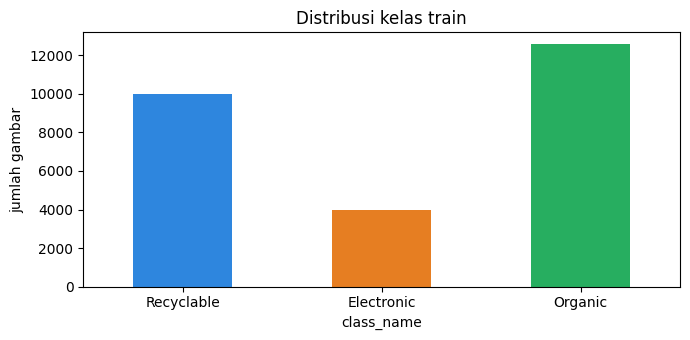

In [8]:
class_counts = train_df["class_name"].value_counts().reindex([CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)])
display(class_counts.to_frame("count").assign(pct=lambda d: (100 * d["count"] / d["count"].sum()).round(2)))
print(f"Imbalance ratio (max/min): {class_counts.max() / class_counts.min():.2f}x")

fig, ax = plt.subplots(figsize=(7, 3.5))
class_counts.plot(kind="bar", ax=ax, color=["#2e86de", "#e67e22", "#27ae60"])
ax.set_title("Distribusi kelas train")
ax.set_ylabel("jumlah gambar")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Pada data penuh, **Electronic adalah kelas minoritas (±15%, imbalance ±3.2×)**. Karena metrik kompetisi macro F1 memberi bobot sama ke tiap kelas, performa Electronic paling menentukan, ini alasan pemakaian `WeightedRandomSampler` + focal loss dengan alpha `1/sqrt(count)` di bagian 4.

### Integritas file: hash sha256 + validasi decode penuh dengan timeout (satu pass baca)

Validasi memakai jalur yang persis sama dengan DataLoader (decode + exif_transpose + convert RGB) dan timeout per file, supaya file yang berpotensi membuat worker macet terdeteksi di sini, bukan setelah training berjalan berjam-jam.

In [9]:
# Proteksi decode-hang: validasi memakai JALUR YANG SAMA dengan DataLoader
# (decode penuh + exif_transpose + convert RGB), dibatasi timeout per file via SIGALRM (Linux/Kaggle).
# File bermasalah dikeluarkan SEBELUM training, bukan ditemukan saat run sudah berjam-jam.
SCAN_VER = 3  # v3: decode memakai Image.draft (jalur baru WasteDataset); cache versi lama otomatis diabaikan


class DecodeTimeout(Exception):
    pass


def _decode_alarm(signum, frame):
    raise DecodeTimeout()


HAS_SIGALRM = hasattr(signal, "SIGALRM")
if not HAS_SIGALRM:
    print("PERINGATAN: platform tanpa SIGALRM (Windows), timeout decode nonaktif; validasi decode tetap jalan.")


def scan_files(records, cache_path):
    """Satu pass per file: sha256(bytes) + decode penuh (exif_transpose + convert RGB) + ukuran piksel.
    Cache berbasis (relpath, size_bytes) dan SCAN_VER supaya rerun (mis. setelah relabeling) cepat."""
    cache = {}
    if Path(cache_path).exists():
        cdf = pd.read_csv(cache_path)
        if "scan_ver" in cdf.columns:
            cache = {(r.relpath, int(r.size_bytes)): dict(r._asdict())
                     for r in cdf.itertuples(index=False) if int(r.scan_ver) == SCAN_VER}
    rows, n_cached = [], 0
    if HAS_SIGALRM:
        signal.signal(signal.SIGALRM, _decode_alarm)
    for rec in tqdm(records, desc=f"scan {Path(cache_path).stem}"):
        p = Path(rec["path"])
        size = p.stat().st_size
        key = (rec["relpath"], size)
        if key in cache:
            rows.append(cache[key])
            n_cached += 1
            continue
        row = {"relpath": rec["relpath"], "size_bytes": size, "sha256": None, "scan_ver": SCAN_VER,
               "decode_ok": False, "width": -1, "height": -1, "error": ""}
        try:
            data = p.read_bytes()
            row["sha256"] = hashlib.sha256(data).hexdigest()
            if HAS_SIGALRM:
                signal.alarm(CFG.DECODE_TIMEOUT_S)
            try:
                with Image.open(BytesIO(data)) as img:
                    row["width"], row["height"] = img.size  # dimensi ASLI dari header (untuk ambang pre-resize)
                    img.draft("RGB", (CFG.MAX_DECODE_SIDE, CFG.MAX_DECODE_SIDE))
                    decoded = ImageOps.exif_transpose(img).convert("RGB")  # jalur persis WasteDataset (dengan draft)
            finally:
                if HAS_SIGALRM:
                    signal.alarm(0)
            row["decode_ok"] = True
        except DecodeTimeout:
            row["error"] = f"DecodeTimeout: decode lebih dari {CFG.DECODE_TIMEOUT_S}s, dikeluarkan dari pipeline"
        except Exception as e:
            row["error"] = f"{type(e).__name__}: {e}"[:200]
        rows.append(row)
        cache[key] = row
    pd.DataFrame(list(cache.values())).to_csv(cache_path, index=False)  # cache = union lama+baru
    out = pd.DataFrame(rows)
    print(f"  {len(out)} file | {n_cached} dari cache | gagal decode/timeout={int((~out['decode_ok'].astype(bool)).sum())}")
    return out


train_scan = scan_files(train_df.to_dict("records"), CFG.EXP_DIR / "scan_train.csv")
test_records = [{"relpath": str(p.relative_to(CFG.DATA_ROOT)), "path": str(p)} for p in test_paths]
test_scan = scan_files(test_records, CFG.EXP_DIR / "scan_test.csv")

scan scan_train:   0%|          | 0/26527 [00:00<?, ?it/s]

  26527 file | 0 dari cache | gagal decode/timeout=0


scan scan_test:   0%|          | 0/1458 [00:00<?, ?it/s]

  1458 file | 0 dari cache | gagal decode/timeout=0


In [10]:
train_scan["decode_ok"] = train_scan["decode_ok"].astype(bool)
test_scan["decode_ok"] = test_scan["decode_ok"].astype(bool)
corrupt_train = train_scan[~train_scan["decode_ok"]]
corrupt_test = test_scan[~test_scan["decode_ok"]]
if len(corrupt_train):
    print("File train corrupt (di-drop dari training):")
    display(corrupt_train)
if len(corrupt_test):
    print("PERHATIAN: file test corrupt, tetap wajib diprediksi; inference memakai fallback gambar hitam:")
    display(corrupt_test)
if corrupt_train.empty and corrupt_test.empty:
    print("Tidak ada file corrupt.")

train_df = train_df.merge(train_scan[["relpath", "sha256", "decode_ok", "width", "height"]], on="relpath", validate="1:1")
n_before = len(train_df)
train_df = train_df[train_df["decode_ok"]].drop(columns=["decode_ok"]).reset_index(drop=True)
print(f"train_df: {n_before} -> {len(train_df)} setelah drop corrupt")

Tidak ada file corrupt.
train_df: 26527 -> 26527 setelah drop corrupt


### Duplikat exact (sha256) - pola `ref/raw_duplicates.py`

- **Dalam train, label sama** → simpan 1 salinan, sisanya di-drop (redundan, dan duplikat lintas-fold membocorkan validasi).
- **Dalam train, label beda (mixed-label)** → semua member di-drop dari training baseline dan ditulis ke `duplicates_mixed_label_review.csv` sebagai antrean **manual relabeling** tim.
- **Train ↔ test** → **dilaporkan saja, tanpa tindakan apa pun terhadap data train**. Juknis §5 melarang memanfaatkan informasi Data Uji untuk training/preprocessing. (Pemanfaatan overlap ini di sisi PREDIKSI test dilakukan di bagian 8, dan itu legal karena tidak menyentuh training.)

Dasar keputusan dari `ref/papers/`: deteksi noise otomatis yang akurat pun tidak menjamin keputusan cleanup yang benar (2407.05528: near-perfect OOD detection justru menurunkan akurasi saat dipakai drop naif; 2410.07689: small-loss selection sub-optimal untuk noise kompleks), jadi grup mixed-label TIDAK di-drop permanen atau di-relabel otomatis, hanya dikeluarkan dari baseline ini dan masuk antrean review manual. Dedup exact same-label adalah praktik standar konstruksi dataset sampah (2602.10500 memakai MD5 + pHash). CSV review memuat kolom `group_id`, `group_size`, `labels_in_group`, `other_members` (path anggota lain untuk perbandingan visual), dan `corrected_label` untuk diisi manual.

In [11]:
grp = train_df.groupby("sha256")
group_size = grp["relpath"].transform("size")
n_labels_in_group = grp["label"].transform("nunique")
dup_mask = group_size > 1
mixed_mask = n_labels_in_group > 1

print(f"Grup duplikat exact dalam train: {train_df.loc[dup_mask, 'sha256'].nunique()} grup ({int(dup_mask.sum())} file)")
print(f"  di antaranya mixed-label     : {train_df.loc[mixed_mask, 'sha256'].nunique()} grup ({int(mixed_mask.sum())} file)")

review_df = train_df[mixed_mask].sort_values(["sha256", "relpath"]).copy()
if len(review_df):
    review_df["group_id"] = review_df.groupby("sha256").ngroup()
    review_df["group_size"] = review_df.groupby("sha256")["relpath"].transform("size")
    review_df["labels_in_group"] = review_df.groupby("sha256")["class_name"].transform(lambda s: "|".join(sorted(set(s))))
    members = review_df.groupby("sha256")["relpath"].agg(list).to_dict()
    review_df["other_members"] = ["|".join(m for m in members[h] if m != r)
                                  for h, r in zip(review_df["sha256"], review_df["relpath"])]
    review_df["corrected_label"] = ""  # diisi manual saat review (kode 0/1/2), input langkah relabel berikutnya
review_path = CFG.EXP_DIR / "duplicates_mixed_label_review.csv"
review_df.to_csv(review_path, index=False)
print(f"Antrean review manual relabeling disimpan: {review_path} ({len(review_df)} baris)")

n_before = len(train_df)
train_df = train_df[~mixed_mask]
train_df = train_df.sort_values("relpath").drop_duplicates("sha256").reset_index(drop=True)
print(f"train_df: {n_before} -> {len(train_df)} setelah dedup")

test_hashes = set(test_scan.loc[test_scan["decode_ok"], "sha256"])
overlap = train_df[train_df["sha256"].isin(test_hashes)]
print(f"\nOverlap exact train<->test: {len(overlap)} file train identik dengan file test (LAPORAN SAJA, tidak ada tindakan).")
if len(overlap):
    display(overlap[["relpath", "class_name"]].head(10))

Grup duplikat exact dalam train: 62 grup (124 file)
  di antaranya mixed-label     : 1 grup (2 file)
Antrean review manual relabeling disimpan: /kaggle/working/experiments/baseline_v1_convnext/duplicates_mixed_label_review.csv (2 baris)
train_df: 26527 -> 26464 setelah dedup

Overlap exact train<->test: 97 file train identik dengan file test (LAPORAN SAJA, tidak ada tindakan).


,relpath,class_name
12749,train/1_Electronic/002784.jpg,Electronic
12976,train/1_Electronic/003013.jpg,Electronic
20327,train/2_Organic/006417.jpg,Organic
20328,train/2_Organic/006418.jpg,Organic
20333,train/2_Organic/006423.jpg,Organic
20335,train/2_Organic/006425.jpg,Organic
20336,train/2_Organic/006426.jpg,Organic
20346,train/2_Organic/006436.jpg,Organic
20347,train/2_Organic/006437.jpg,Organic
20348,train/2_Organic/006438.jpg,Organic


### Pre-resize salinan gambar raksasa (>=8MP)

Audit menemukan 233 gambar >=8MP dan SEMUANYA di kelas Electronic (hingga 8000x6000, ~137MB per decode RGB), padahal Electronic justru di-oversample WeightedRandomSampler sehingga file terberat paling sering ditarik ke batch; ini kontributor utama GPU idle di run sebelumnya. Salinan diperkecil ke sisi terpanjang 1024px (masih jauh di atas input model 224px). Preprocessing Data Latih tanpa memakai informasi Data Uji diperbolehkan juknis §5. File asli TIDAK diubah; train_df dialihkan ke salinan di `train_resized/`.

Pasca insiden RAM OOM: cell ini sekarang **fail-fast** (assertion menghentikan run dengan pesan jelas bila substitusi path gagal, bukan diam-diam melatih file raksasa). Pengukuran proses terpisah: decode satu file 8000x6000 memuncak **~569MB RSS** tanpa draft vs **~54MB** dengan `Image.draft(1024)`; empat worker yang kebetulan memegang file raksasa bersamaan berarti burst ~2.3GB. Karena itu `Image.draft` juga dipasang permanen di `WasteDataset` dan scan sebagai lapisan pengaman kedua, dan `prefetch_factor` diturunkan 4 -> 2 sebagai margin.

In [12]:
t_resize = time.time()
big_mask = (train_df["width"].astype(int) * train_df["height"].astype(int)) >= CFG.RESIZE_MP_THRESHOLD
resized_root = CFG.OUTPUT_ROOT / "train_resized"
n_big = int(big_mask.sum())
sample_before = train_df.loc[big_mask, "path"].head(3).tolist()
print(f"pre-resize: {n_big} gambar >= {CFG.RESIZE_MP_THRESHOLD / 1e6:.0f}MP terdeteksi", flush=True)
n_new = 0
for idx in tqdm(train_df.index[big_mask], desc="pre-resize"):
    dst = resized_root / train_df.at[idx, "relpath"]
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        img = Image.open(train_df.at[idx, "path"])
        img.draft("RGB", (CFG.RESIZE_MAX_SIDE, CFG.RESIZE_MAX_SIDE))  # JPEG: decode tereduksi, hemat RAM dan waktu
        img = ImageOps.exif_transpose(img).convert("RGB")
        img.thumbnail((CFG.RESIZE_MAX_SIDE, CFG.RESIZE_MAX_SIDE), Image.Resampling.LANCZOS)
        if dst.suffix.lower() in {".jpg", ".jpeg"}:
            img.save(dst, quality=95)
        else:
            img.save(dst)
        n_new += 1
    train_df.at[idx, "path"] = str(dst)

# Fail-fast: substitusi path WAJIB terverifikasi; kalau gagal run BERHENTI di sini dengan pesan jelas,
# bukan diam-diam lanjut melatih dengan file raksasa (root cause OOM run sebelumnya).
if n_big:
    redirected = train_df.loc[big_mask, "path"]
    assert redirected.str.startswith(str(resized_root)).all(), \
        "pre-resize GAGAL: sebagian path masih menunjuk file asli raksasa"
    _missing = [p for p in redirected if not Path(p).is_file()]
    assert not _missing, f"pre-resize GAGAL: {len(_missing)} salinan tidak ada di disk, contoh: {_missing[:3]}"
    with Image.open(redirected.iloc[0]) as _im:
        assert max(_im.size) <= CFG.RESIZE_MAX_SIDE, f"pre-resize GAGAL: salinan masih berukuran {_im.size}"
    print("bukti redirect | SEBELUM:", sample_before[0])
    print("bukti redirect | SESUDAH:", redirected.iloc[0])
assert not train_df.loc[~big_mask, "path"].str.startswith(str(resized_root)).any(), \
    "path gambar normal ikut teralihkan, tidak seharusnya"
print(f"pre-resize SELESAI: {n_big} dialihkan ({n_new} baru dibuat) dalam {time.time() - t_resize:.1f}s | RSS {rss_gb():.1f}GB", flush=True)

pre-resize: 233 gambar >= 8MP terdeteksi


pre-resize:   0%|          | 0/233 [00:00<?, ?it/s]

bukti redirect | SEBELUM: /kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset/train/1_Electronic/000022.jpeg
bukti redirect | SESUDAH: /kaggle/working/train_resized/train/1_Electronic/000022.jpeg
pre-resize SELESAI: 233 dialihkan (233 baru dibuat) dalam 31.2s | RSS 1.0GB


### Sampel gambar, resolusi, dan variasi brightness/contrast

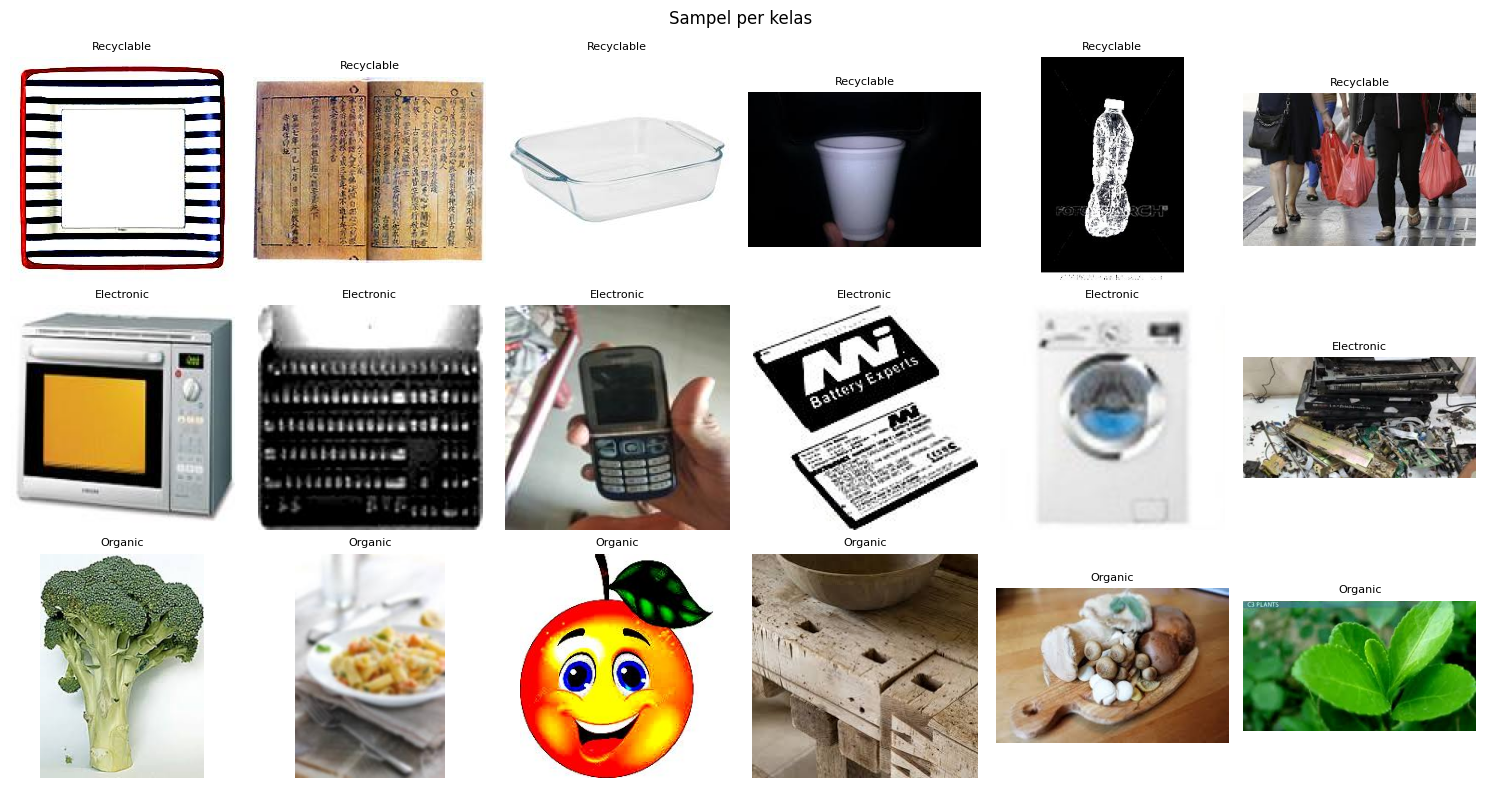

Statistik resolusi train (dari hasil scan):


,width,height
min,51,69
25%,220,174
50%,254,194
75%,276,225
max,8000,6000


Ukuran unik terbanyak:
width  height
225    225       4232
150    150       2647
275    183       2563
259    194       1725
300    168        944
183    275        497
194    259        366
276    183        352


In [13]:
seed_everything(CFG.SEED, deterministic=CFG.CUDNN_DETERMINISTIC)
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for i in range(CFG.NUM_CLASSES):
    subset = train_df[train_df["label"] == i]
    samples = subset.sample(min(6, len(subset)), random_state=CFG.SEED)
    for j in range(6):
        ax = axes[i, j]
        ax.axis("off")
        if j < len(samples):
            row = samples.iloc[j]
            img = ImageOps.exif_transpose(Image.open(row["path"])).convert("RGB")
            ax.imshow(img)
            ax.set_title(row["class_name"], fontsize=8)
plt.suptitle("Sampel per kelas")
plt.tight_layout()
plt.show()

print("Statistik resolusi train (dari hasil scan):")
display(train_df[["width", "height"]].describe().loc[["min", "25%", "50%", "75%", "max"]].astype(int))
print("Ukuran unik terbanyak:")
print(train_df.groupby(["width", "height"]).size().sort_values(ascending=False).head(8).to_string())

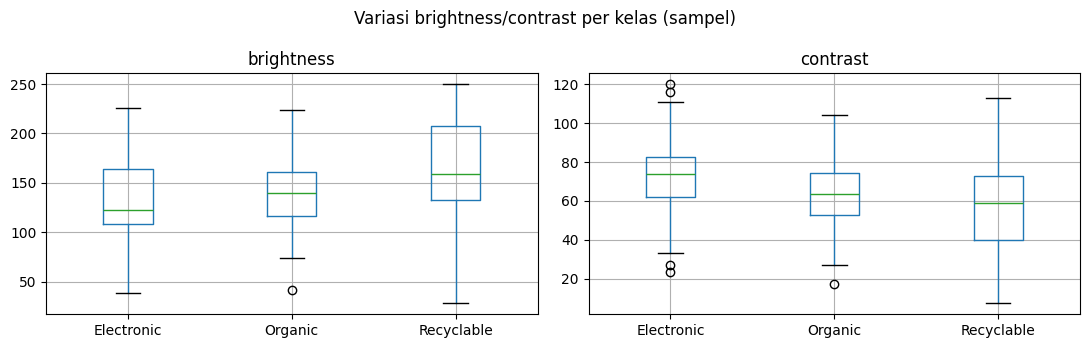

In [14]:
def brightness_contrast(path):
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB").resize((96, 96))
    st = ImageStat.Stat(img)
    return sum(st.mean[:3]) / 3, sum(st.stddev[:3]) / 3


bc_rows = []
for label_code in range(CFG.NUM_CLASSES):
    subset = train_df[train_df["label"] == label_code]
    subset = subset.sample(min(60, len(subset)), random_state=CFG.SEED)
    for _, r in subset.iterrows():
        b, c = brightness_contrast(r["path"])
        bc_rows.append({"class_name": r["class_name"], "brightness": b, "contrast": c})
bc_df = pd.DataFrame(bc_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bc_df.boxplot(column="brightness", by="class_name", ax=axes[0])
bc_df.boxplot(column="contrast", by="class_name", ax=axes[1])
for ax in axes:
    ax.set_xlabel("")
plt.suptitle("Variasi brightness/contrast per kelas (sampel)")
plt.tight_layout()
plt.show()

Spread brightness/contrast intra-kelas lebar (foto berasal dari banyak sumber dengan exposure dan ketajaman berbeda), konsisten dengan tinjauan manual sampel. Ini justifikasi augmentasi **ColorJitter brightness/contrast agresif + GaussianBlur** di bagian 4.

## 3. Stratified 5-Fold Cross-Validation

Pola `ref/best-public-findit-dinov2-v0.ipynb`: `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, proporsi kelas terjaga di tiap fold (macro F1 sensitif terhadap representasi kelas minoritas). Assignment fold disimpan ke CSV untuk reprodusibilitas dan perbandingan antar eksperimen.

In [15]:
skf = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
train_df["fold"] = -1
for fold, (_, val_idx) in enumerate(skf.split(train_df["relpath"], train_df["label"])):
    train_df.loc[val_idx, "fold"] = fold
assert (train_df["fold"] >= 0).all()

folds_path = CFG.EXP_DIR / "folds.csv"
train_df[["relpath", "class_name", "label", "fold"]].to_csv(folds_path, index=False)
print("Fold assignment disimpan:", folds_path)
display(pd.crosstab(train_df["fold"], train_df["class_name"]))

Fold assignment disimpan: /kaggle/working/experiments/baseline_v1_convnext/folds.csv


class_name,Electronic,Organic,Recyclable
fold,,,
0,786,2509,1998
1,786,2509,1998
2,786,2509,1998
3,786,2509,1998
4,787,2508,1997


## 4. Dataset, Augmentasi Online, dan Loss

Augmentasi dilakukan **online** (per batch saat training); offline augmentation ala `ref/preprocess_dataset_v1.py` tidak cocok untuk 26.5k gambar. Brightness/contrast agresif + blur dipakai karena variasi exposure dan blur antar submisi peserta signifikan (lihat EDA di atas). Loss mengikuti pola `ref/ver34_clean_end_to_end.ipynb`: `FocalLossWithSmoothing` dengan alpha `1/sqrt(count)` per kelas + `WeightedRandomSampler`.

### Modularisasi dataset dan transform (bdc_lib.py)

`WasteDataset` dan transform dipindah ke module `bdc_lib.py` (ditulis oleh cell di bawah, lalu di-import balik). Aturan panitia eksplisit memperbolehkan struktur kode modular. Dua tujuan: DataLoader worker dengan start method spawn (Windows) bisa pickle kelas dataset karena kelasnya hidup di module file, bukan di namespace notebook, dan kode jadi lebih mudah diaudit. Isi augmentasi TIDAK berubah dari versi sebelumnya.

In [16]:
%%writefile bdc_lib.py
"""Dataset dan transform untuk BDC Satria Data 2026.

Dipisah dari notebook supaya kelas dataset picklable oleh DataLoader worker
(start method spawn di Windows butuh import dari module file) dan mudah diaudit.
"""
import torch
from PIL import Image, ImageOps
from torch.utils.data import Dataset
from torchvision import transforms


class WasteDataset(Dataset):
    def __init__(self, df, transform, with_target=True, safe_mode=False, img_size=224, max_decode_side=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.with_target = with_target
        self.safe_mode = safe_mode  # True untuk test: file gagal decode -> gambar hitam (tetap wajib diprediksi)
        self.img_size = img_size
        self.max_decode_side = max_decode_side

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        try:
            image = Image.open(row["path"])
            if self.max_decode_side:
                # JPEG: decoder membaca langsung pada resolusi tereduksi (1/2, 1/4, 1/8) sehingga file
                # raksasa TIDAK PERNAH dimuat resolusi penuh ke RAM (terukur: 569MB -> 54MB per file 48MP).
                # No-op untuk PNG/format lain. Lapisan pengaman kedua di samping pre-resize.
                image.draft("RGB", (self.max_decode_side, self.max_decode_side))
            image = ImageOps.exif_transpose(image).convert("RGB")
        except Exception:
            if not self.safe_mode:
                raise
            image = Image.new("RGB", (self.img_size, self.img_size))
        sample = {"image": self.transform(image)}
        if self.with_target:
            sample["target"] = torch.tensor(int(row["label"]), dtype=torch.long)
        return sample


def build_transforms(img_size, mean, std):
    """Augmentasi online. Parameter identik dengan baseline v1 (jangan ubah tanpa eksperimen baru)."""
    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.65, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        # brightness/contrast agresif dipertahankan: itu yang menangani variasi exposure signifikan di data.
        # hue=0: hue jitter dihapus karena konversi warna per gambar mahal di CPU (penyebab GPU idle di Kaggle).
        transforms.RandomApply([transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.25, hue=0.0)], p=0.8),
        # GaussianBlur dinonaktifkan untuk baseline v1 (beban CPU per gambar tinggi). Aktifkan kembali
        # dengan membuka komentar baris berikut bila throughput sudah terbukti aman:
        # transforms.RandomApply([transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0))], p=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    eval_transform = transforms.Compose([
        transforms.Resize(int(img_size * 1.14)),
        transforms.CenterCrop(img_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    return train_transform, eval_transform


def worker_init_fn(worker_id):
    """Tiap DataLoader worker mewarisi thread intra-op torch default (= jumlah vCPU).
    Di mesin 4 vCPU dengan 4 worker itu memicu oversubscription CPU; 1 thread per worker
    menghentikan rebutan CPU antar worker."""
    torch.set_num_threads(1)

Writing bdc_lib.py


In [17]:
import importlib

import bdc_lib
importlib.reload(bdc_lib)  # pastikan versi terbaru terpakai saat cell writefile di atas berubah
from bdc_lib import WasteDataset, build_transforms, worker_init_fn

print("modul dataset:", bdc_lib.__file__)

# mean/std mengikuti konfigurasi pretrained timm (probe tanpa mengunduh bobot)
probe = timm.create_model(CFG.MODEL_ID, pretrained=False, num_classes=0)
data_cfg = resolve_model_data_config(probe)
MEAN, STD = tuple(data_cfg["mean"]), tuple(data_cfg["std"])
del probe
print("normalisasi:", MEAN, STD)

train_transform, eval_transform = build_transforms(CFG.IMG_SIZE, MEAN, STD)
print("train_transform:")
print(train_transform)

modul dataset: /kaggle/working/bdc_lib.py
normalisasi: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)
train_transform:
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.65, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomApply(
    p=0.8
    ColorJitter(brightness=(0.6, 1.4), contrast=(0.6, 1.4), saturation=(0.75, 1.25), hue=None)
)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


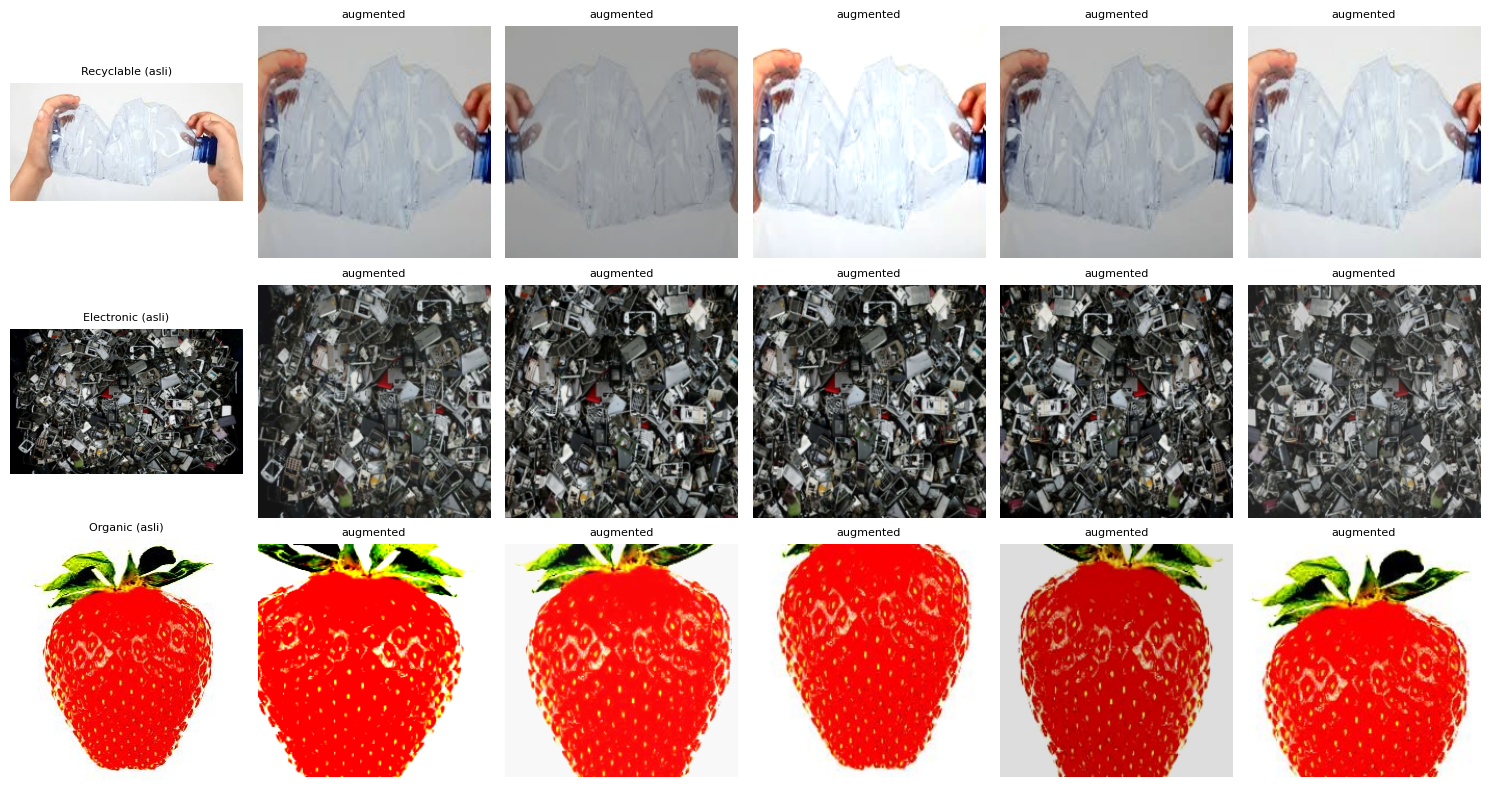

In [18]:
# Sanity check visual augmentasi: 1 gambar per kelas, 5 variasi augmented
viz_tf = transforms.Compose(train_transform.transforms[:-2])  # tanpa ToTensor/Normalize
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for i in range(CFG.NUM_CLASSES):
    row = train_df[train_df["label"] == i].iloc[0]
    img = ImageOps.exif_transpose(Image.open(row["path"])).convert("RGB")
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{row['class_name']} (asli)", fontsize=8)
    for j in range(1, 6):
        axes[i, j].imshow(viz_tf(img))
        axes[i, j].set_title("augmented", fontsize=8)
    for j in range(6):
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

In [19]:
class FocalLossWithSmoothing(nn.Module):
    """Pola ref/ver34_clean_end_to_end.ipynb."""

    def __init__(self, num_classes, alpha, gamma, smoothing):
        super().__init__()
        self.gamma = gamma
        self.smoothing = smoothing
        self.num_classes = num_classes
        self.alpha = alpha

    def forward(self, inputs, targets):
        with torch.no_grad():
            true_dist = torch.zeros_like(inputs)
            true_dist.fill_(self.smoothing / (self.num_classes - 1))
            true_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        log_p = F.log_softmax(inputs, dim=-1)
        p = log_p.exp()
        focal_weight = (1.0 - p).pow(self.gamma)
        focal_weight = focal_weight * self.alpha[targets].view(-1, 1)
        return (-focal_weight * true_dist * log_p).sum(dim=-1).mean()


def build_criterion(fold_train_df):
    counts = fold_train_df["label"].value_counts()
    weights = torch.tensor([1.0 / math.sqrt(counts.get(c, 1)) for c in range(CFG.NUM_CLASSES)],
                           dtype=torch.float32, device=DEVICE)
    weights /= weights.mean()  # alpha = 1/sqrt(count), dinormalisasi
    return FocalLossWithSmoothing(CFG.NUM_CLASSES, alpha=weights, gamma=CFG.FOCAL_GAMMA,
                                  smoothing=CFG.LABEL_SMOOTHING), weights


def build_sampler(fold_train_df, seed):
    counts = fold_train_df["label"].value_counts().to_dict()
    sample_weights = fold_train_df["label"].map(lambda c: 1.0 / counts[c]).to_numpy(dtype=np.float64).copy()
    gen = torch.Generator()
    gen.manual_seed(seed)
    return WeightedRandomSampler(torch.DoubleTensor(sample_weights), num_samples=len(sample_weights),
                                 replacement=True, generator=gen)

## 5. Model - ConvNeXtV2-Base Full Fine-tune

Semua parameter di-train. LR backbone < LR head (pola ver34), epoch pertama backbone dibekukan agar head yang baru diinisialisasi stabil dulu. Cell ini juga memicu unduhan bobot pretrained (±350MB, sekali saja) supaya gagal cepat kalau ada masalah jaringan/autentikasi.

In [20]:
def build_model():
    return timm.create_model(CFG.MODEL_ID, pretrained=True, num_classes=CFG.NUM_CLASSES,
                             drop_path_rate=CFG.DROP_PATH_RATE)


def split_param_groups(model):
    head_params = [p for n, p in model.named_parameters() if n.startswith("head.")]
    backbone_params = [p for n, p in model.named_parameters() if not n.startswith("head.")]
    assert head_params, "Head tidak terdeteksi, cek penamaan parameter model"
    return backbone_params, head_params


def set_backbone_trainable(model, trainable):
    for n, p in model.named_parameters():
        if not n.startswith("head."):
            p.requires_grad = trainable


class AutocastForward(nn.Module):
    """autocast bersifat thread-local: DataParallel menjalankan forward replika di thread terpisah,
    sehingga autocast dari run_epoch TIDAK berlaku di sana dan replika jatuh ke fp32 (lambat di T4).
    Wrapper ini menerapkan autocast DI DALAM forward supaya aktif di tiap replika."""

    def __init__(self, module):
        super().__init__()
        self.m = module

    def forward(self, x):
        with torch.amp.autocast("cuda", dtype=torch.float16):
            return self.m(x)


def maybe_data_parallel(model):
    """Kaggle T4 x2: DataParallel membagi tiap batch antar GPU (CFG.BATCH_SIZE = total batch)."""
    if DEVICE.type == "cuda" and N_GPUS > 1 and CFG.USE_DATA_PARALLEL:
        print(f"nn.DataParallel aktif ({N_GPUS} GPU), autocast dibungkus ke dalam forward replika")
        return nn.DataParallel(AutocastForward(model))
    return model


def unwrap(model):
    # split_param_groups/set_backbone_trainable/state_dict selalu bekerja pada model dasar,
    # supaya checkpoint bebas prefix 'module.'/'m.' dan kompatibel single-GPU
    if isinstance(model, nn.DataParallel):
        model = model.module
    if isinstance(model, AutocastForward):
        model = model.m
    return model


_m = build_model()
bb, hd = split_param_groups(_m)
print(f"total params    : {sum(p.numel() for p in _m.parameters()) / 1e6:.1f}M")
print(f"backbone params : {sum(p.numel() for p in bb) / 1e6:.1f}M | head params: {sum(p.numel() for p in hd) / 1e6:.3f}M")
del _m

model.safetensors:   0%|          | 0.00/355M [00:00<?, ?B/s]

total params    : 87.7M
backbone params : 87.7M | head params: 0.005M


In [21]:
def run_epoch(model, loader, criterion=None, optimizer=None, scaler=None, use_tta=False, desc=""):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    losses, all_targets, all_preds, all_probs = [], [], [], []
    if is_train:
        optimizer.zero_grad(set_to_none=True)
    t_start = time.time()
    rss_start = rss_gb()
    progress = tqdm(loader, desc=desc or ("train" if is_train else "valid"), leave=False)
    for step, batch in enumerate(progress, start=1):
        images = batch["image"].to(DEVICE, non_blocking=True)
        targets = batch["target"].to(DEVICE, non_blocking=True) if "target" in batch else None
        amp_ctx = torch.amp.autocast("cuda", dtype=torch.float16) if DEVICE.type == "cuda" else nullcontext()
        with torch.set_grad_enabled(is_train), amp_ctx:
            logits = model(images)
            if use_tta and not is_train:
                logits = 0.5 * (logits + model(torch.flip(images, dims=[3])))
            loss = criterion(logits, targets) if (criterion is not None and targets is not None) else None
        if is_train:
            scaled = loss / CFG.GRAD_ACCUM_STEPS
            if scaler is not None:
                scaler.scale(scaled).backward()
                if step % CFG.GRAD_ACCUM_STEPS == 0 or step == len(loader):
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
            else:
                scaled.backward()
                if step % CFG.GRAD_ACCUM_STEPS == 0 or step == len(loader):
                    optimizer.step()
                    optimizer.zero_grad(set_to_none=True)
        probs = torch.softmax(logits.float(), dim=1).detach().cpu().numpy()
        all_probs.append(probs)
        all_preds.extend(probs.argmax(axis=1).tolist())
        if loss is not None:
            losses.append(loss.item())
            all_targets.extend(targets.cpu().numpy().tolist())
            progress.set_postfix(loss=f"{np.mean(losses):.4f}")
        if step % CFG.HEARTBEAT_EVERY_BATCH == 0 or step == len(loader):
            elapsed = time.time() - t_start
            pct = 100.0 * step / max(len(loader), 1)
            # tqdm berbasis widget tidak tampil di log commit Kaggle; baris flush ini selalu tampil
            _rss_now = rss_gb()
            print(f"[hb] {desc or 'epoch'}: batch {step}/{len(loader)} ({pct:.0f}%) | "
                  f"{elapsed / step:.2f}s/iter | RSS {_rss_now:.1f}GB (delta {_rss_now - rss_start:+.1f}GB)", flush=True)
            if WANDB_ENABLED and wandb.run is not None:
                wandb.log({"hb/pct": pct, "hb/sec_per_iter": elapsed / step, "hb/batch": step,
                           "hb/rss_gb": _rss_now, "hb/rss_delta_gb": _rss_now - rss_start})
    out = {"loss": float(np.mean(losses)) if losses else float("nan"),
           "preds": np.array(all_preds),
           "probs": np.concatenate(all_probs) if all_probs else None}
    if all_targets:
        out["targets"] = np.array(all_targets)
        out["macro_f1"] = float(f1_score(out["targets"], out["preds"], average="macro"))
    return out

## 6. Training 5-Fold

⚠️ **Cell berikut adalah training loop panjang.** Dengan `SMOKE_TEST=True` hanya berjalan 1 fold × 1 epoch pada subset (verifikasi pipeline). Untuk run sebenarnya: set `SMOKE_TEST=False` di cell konfigurasi, lalu jalankan headless via *Save Version -> Save & Run All (Commit)* di Kaggle supaya run jalan tanpa sesi interaktif yang harus dipantau. Default `TRAIN_FOLDS = [0]` agar run malam pertama realistis selesai dalam satu sesi; kembalikan ke `[0, 1, 2, 3, 4]` untuk OOF penuh setelah kecepatan dan hasil fold 0 terverifikasi. Di Kaggle T4 ×2, `nn.DataParallel` otomatis aktif (`CFG.BATCH_SIZE` = total batch lintas GPU, naikkan bila memori longgar). Setelah run selesai, unduh isi `/kaggle/working` (checkpoint, history, folds, OOF, log, submission).

**Fix memory leak (2026-07-05)**: run sebelumnya bocor RAM ~48MB/batch sampai kernel mati di batch ~500. Replikasi CPU 225 batch membuktikan loop dasar bersih (RSS datar; sensus gc hanya mencatat akumulasi probabilitas 96 byte/batch yang memang disengaja), jadi sumbernya komponen khusus jalur CUDA: cache pinned-memory dan/atau broadcast parameter per iterasi DataParallel (staging via host bila P2P nonaktif; 44MB fp16 params/iter cocok dengan laju leak terukur). Keduanya dimatikan (`pin_memory=False`, `USE_DATA_PARALLEL=False`), nol biaya karena run loader-bound. Heartbeat kini menampilkan delta RSS sejak awal epoch; pada run berikutnya delta harus mendekati nol setelah warm-up.

**Ablation TTA**: setelah checkpoint terbaik tiap fold dimuat, val macro F1 dihitung dua kali, dengan dan tanpa TTA horizontal flip, dan keduanya dicatat ke `EXPERIMENTS_LOG.md`. TTA tidak selalu meningkatkan performa; beberapa studi menemukan penurunan signifikan pada arsitektur tertentu (mekanismenya terkait mismatch statistik BatchNorm terhadap input teraugmentasi; ConvNeXtV2 memakai LayerNorm sehingga kemungkinan tidak terdampak mekanisme yang sama, tapi tetap dikonfirmasi lewat data, bukan diasumsikan).

In [22]:
fold_summaries = []
history_rows = []
oof_probs = np.full((len(train_df), CFG.NUM_CLASSES), np.nan)

for fold in CFG.TRAIN_FOLDS:
    print(f"\n===== FOLD {fold} =====")
    seed_everything(CFG.SEED + fold, deterministic=CFG.CUDNN_DETERMINISTIC)
    tr_df = train_df[train_df["fold"] != fold].reset_index(drop=True)
    va_df = train_df[train_df["fold"] == fold].reset_index(drop=True)
    va_positions = np.where((train_df["fold"] == fold).to_numpy())[0]

    train_loader = DataLoader(WasteDataset(tr_df, train_transform, max_decode_side=CFG.MAX_DECODE_SIDE),
                              batch_size=CFG.BATCH_SIZE,
                              sampler=build_sampler(tr_df, CFG.SEED + fold), shuffle=False,
                              num_workers=CFG.NUM_WORKERS, pin_memory=False,  # dimatikan: cache pinned-memory suspek leak; H2D pageable hanya ~3ms lebih lambat/batch
                              persistent_workers=CFG.NUM_WORKERS > 0,
                              prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,  # 4->2: margin RAM pasca-OOM
                              worker_init_fn=worker_init_fn if CFG.NUM_WORKERS > 0 else None)
    val_loader = DataLoader(WasteDataset(va_df, eval_transform, max_decode_side=CFG.MAX_DECODE_SIDE),
                            batch_size=CFG.BATCH_SIZE * 2,
                            shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=False,  # dimatikan: cache pinned-memory suspek leak; H2D pageable hanya ~3ms lebih lambat/batch
                            persistent_workers=CFG.NUM_WORKERS > 0,
                            prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,  # 4->2: margin RAM pasca-OOM
                            worker_init_fn=worker_init_fn if CFG.NUM_WORKERS > 0 else None)

    model = maybe_data_parallel(build_model().to(DEVICE))
    criterion, class_alpha = build_criterion(tr_df)
    print("alpha per kelas:", {CFG.LABEL_NAMES[i]: round(float(a), 3) for i, a in enumerate(class_alpha)})
    if WANDB_ENABLED:
        wandb.init(project=WANDB_PROJECT,
                   name=f"{CFG.RUN_NAME}-fold{fold}" + ("-smoke" if CFG.SMOKE_TEST else ""),
                   config={"model_id": CFG.MODEL_ID, "img_size": CFG.IMG_SIZE, "batch_size": CFG.BATCH_SIZE,
                           "epochs": CFG.EPOCHS, "backbone_lr": CFG.BACKBONE_LR, "head_lr": CFG.HEAD_LR,
                           "num_workers": CFG.NUM_WORKERS, "fold": fold, "smoke_test": CFG.SMOKE_TEST},
                   reinit=True)
    backbone_params, head_params = split_param_groups(unwrap(model))
    optimizer = torch.optim.AdamW([
        {"params": backbone_params, "lr": CFG.BACKBONE_LR},
        {"params": head_params, "lr": CFG.HEAD_LR},
    ], weight_decay=CFG.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.EPOCHS)
    scaler = torch.amp.GradScaler("cuda") if DEVICE.type == "cuda" else None

    best = {"macro_f1": -1.0, "epoch": -1, "state": None}
    no_improve = 0
    # checkpoint smoke diberi prefix supaya TIDAK PERNAH terambil oleh cell submission pada full run;
    # disimpan SETIAP kali val macro F1 membaik supaya sesi yang mati tidak kehilangan semuanya
    ckpt_path = CFG.EXP_DIR / f"{'smoke_' if CFG.SMOKE_TEST else ''}fold{fold}_best.pt"
    for epoch in range(1, CFG.EPOCHS + 1):
        set_backbone_trainable(unwrap(model), epoch > CFG.FREEZE_BACKBONE_EPOCHS)
        tr_m = run_epoch(model, train_loader, criterion, optimizer, scaler, desc=f"f{fold} e{epoch} train")
        va_m = run_epoch(model, val_loader, criterion, use_tta=CFG.USE_VAL_TTA, desc=f"f{fold} e{epoch} valid")
        scheduler.step()
        history_rows.append({"fold": fold, "epoch": epoch,
                             "train_loss": tr_m["loss"], "train_macro_f1": tr_m["macro_f1"],
                             "val_loss": va_m["loss"], "val_macro_f1": va_m["macro_f1"]})
        pd.DataFrame(history_rows).to_csv(CFG.EXP_DIR / "history.csv", index=False)  # ditulis tiap epoch
        print(f"epoch {epoch:02d} | train_f1={tr_m['macro_f1']:.4f} | val_f1={va_m['macro_f1']:.4f} | val_loss={va_m['loss']:.4f}", flush=True)
        if WANDB_ENABLED and wandb.run is not None:
            wandb.log({"epoch": epoch, "train/loss": tr_m["loss"], "train/macro_f1": tr_m["macro_f1"],
                       "val/loss": va_m["loss"], "val/macro_f1": va_m["macro_f1"]})
        if va_m["macro_f1"] > best["macro_f1"]:
            best = {"macro_f1": va_m["macro_f1"], "epoch": epoch, "state": copy.deepcopy(unwrap(model).state_dict())}
            no_improve = 0
            torch.save({"state_dict": best["state"], "model_id": CFG.MODEL_ID, "img_size": CFG.IMG_SIZE,
                        "fold": fold, "best_epoch": best["epoch"], "val_macro_f1": best["macro_f1"],
                        "mean": MEAN, "std": STD, "smoke": CFG.SMOKE_TEST}, ckpt_path)
        else:
            no_improve += 1
            if no_improve >= CFG.EARLY_STOPPING_PATIENCE:
                print(f"early stopping di epoch {epoch}")
                break

    unwrap(model).load_state_dict(best["state"])
    # Ablation TTA: TTA tidak selalu membantu (tergantung arsitektur), jadi divalidasi empiris per fold
    val_no_tta = run_epoch(model, val_loader, criterion, use_tta=False, desc=f"f{fold} best valid tanpa-TTA")
    val_tta = run_epoch(model, val_loader, criterion, use_tta=True, desc=f"f{fold} best valid TTA")
    print(f"fold {fold} ablation TTA: tanpa-TTA={val_no_tta['macro_f1']:.4f} | TTA={val_tta['macro_f1']:.4f}")
    final_val = val_tta if CFG.USE_VAL_TTA else val_no_tta
    oof_probs[va_positions] = final_val["probs"]
    per_class = f1_score(final_val["targets"], final_val["preds"], average=None, labels=list(range(CFG.NUM_CLASSES)))

    # tulis ulang checkpoint dengan metrik final (state sama dengan simpanan saat improvement terakhir)
    torch.save({"state_dict": best["state"], "model_id": CFG.MODEL_ID, "img_size": CFG.IMG_SIZE,
                "fold": fold, "best_epoch": best["epoch"], "val_macro_f1": final_val["macro_f1"],
                "mean": MEAN, "std": STD, "smoke": CFG.SMOKE_TEST}, ckpt_path)
    fold_summaries.append({"fold": fold, "best_epoch": best["epoch"],
                           "val_macro_f1": final_val["macro_f1"],
                           "val_macro_f1_no_tta": val_no_tta["macro_f1"],
                           "val_macro_f1_tta": val_tta["macro_f1"],
                           **{f"f1_{CFG.LABEL_NAMES[i]}": float(per_class[i]) for i in range(CFG.NUM_CLASSES)}})
    pd.DataFrame(fold_summaries).to_csv(CFG.EXP_DIR / "fold_summary.csv", index=False)  # ditulis tiap fold
    print(f"fold {fold}: best_epoch={best['epoch']} val_macro_f1={final_val['macro_f1']:.4f} | ckpt: {ckpt_path.name}")
    if WANDB_ENABLED and wandb.run is not None:
        wandb.log({"ablation/val_macro_f1_no_tta": val_no_tta["macro_f1"],
                   "ablation/val_macro_f1_tta": val_tta["macro_f1"], "best_epoch": best["epoch"]})
        wandb.finish()
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

fold_summary_df = pd.DataFrame(fold_summaries)
pd.DataFrame(history_rows).to_csv(CFG.EXP_DIR / "history.csv", index=False)
fold_summary_df.to_csv(CFG.EXP_DIR / "fold_summary.csv", index=False)
display(fold_summary_df)


===== FOLD 0 =====
alpha per kelas: {'Recyclable': 0.86, 'Electronic': 1.372, 'Organic': 0.768}


f0 e1 train:   0%|          | 0/662 [00:00<?, ?it/s]

[hb] f0 e1 train: batch 50/662 (8%) | 0.42s/iter | RSS 2.5GB (delta +0.6GB)
[hb] f0 e1 train: batch 100/662 (15%) | 0.30s/iter | RSS 2.5GB (delta +0.6GB)
[hb] f0 e1 train: batch 150/662 (23%) | 0.27s/iter | RSS 2.5GB (delta +0.6GB)
[hb] f0 e1 train: batch 200/662 (30%) | 0.25s/iter | RSS 2.5GB (delta +0.7GB)
[hb] f0 e1 train: batch 250/662 (38%) | 0.24s/iter | RSS 2.5GB (delta +0.7GB)
[hb] f0 e1 train: batch 300/662 (45%) | 0.23s/iter | RSS 2.5GB (delta +0.7GB)
[hb] f0 e1 train: batch 350/662 (53%) | 0.23s/iter | RSS 2.5GB (delta +0.7GB)
[hb] f0 e1 train: batch 400/662 (60%) | 0.22s/iter | RSS 2.5GB (delta +0.7GB)
[hb] f0 e1 train: batch 450/662 (68%) | 0.22s/iter | RSS 2.5GB (delta +0.7GB)
[hb] f0 e1 train: batch 500/662 (76%) | 0.22s/iter | RSS 2.5GB (delta +0.7GB)
[hb] f0 e1 train: batch 550/662 (83%) | 0.22s/iter | RSS 2.5GB (delta +0.7GB)
[hb] f0 e1 train: batch 600/662 (91%) | 0.22s/iter | RSS 2.5GB (delta +0.7GB)
[hb] f0 e1 train: batch 650/662 (98%) | 0.22s/iter | RSS 2.5GB (de

f0 e1 valid:   0%|          | 0/83 [00:00<?, ?it/s]

[hb] f0 e1 valid: batch 50/83 (60%) | 1.01s/iter | RSS 2.6GB (delta +0.1GB)
[hb] f0 e1 valid: batch 83/83 (100%) | 1.02s/iter | RSS 2.6GB (delta +0.1GB)
epoch 01 | train_f1=0.9376 | val_f1=0.9630 | val_loss=0.1215


...

f4 best valid tanpa-TTA:   0%|          | 0/83 [00:00<?, ?it/s]

[hb] f4 best valid tanpa-TTA: batch 50/83 (60%) | 0.41s/iter | RSS 3.1GB (delta +0.0GB)
[hb] f4 best valid tanpa-TTA: batch 83/83 (100%) | 0.40s/iter | RSS 3.1GB (delta +0.0GB)


f4 best valid TTA:   0%|          | 0/83 [00:00<?, ?it/s]

[hb] f4 best valid TTA: batch 50/83 (60%) | 0.79s/iter | RSS 3.1GB (delta +0.0GB)
[hb] f4 best valid TTA: batch 83/83 (100%) | 0.77s/iter | RSS 3.1GB (delta +0.0GB)
fold 4 ablation TTA: tanpa-TTA=0.9784 | TTA=0.9794
fold 4: best_epoch=6 val_macro_f1=0.9794 | ckpt: fold4_best.pt


,fold,best_epoch,val_macro_f1,val_macro_f1_no_tta,val_macro_f1_tta,f1_Recyclable,f1_Electronic,f1_Organic
0,0,3,0.981452,0.981006,0.981452,0.974052,0.990524,0.979780
1,1,6,0.985267,0.984399,0.985267,0.979765,0.989220,0.986816
2,2,8,0.980709,0.980859,0.980709,0.973121,0.989822,0.979183
3,3,8,0.982384,0.981942,0.982384,0.976779,0.987967,0.982407
4,4,6,0.979387,0.978391,0.979387,0.971827,0.987952,0.978383


## 7. Evaluasi Out-of-Fold (OOF)

Estimasi performa lokal, dasar keputusan submit/tidak (hanya ada 3 kesempatan submission, tidak bisa ditarik ulang).

OOF tersedia untuk 26464/26464 baris (fold dilatih: [0, 1, 2, 3, 4])

OOF macro F1 (pooled)      : 0.9818
Per-fold macro F1          : [np.float64(0.9815), np.float64(0.9853), np.float64(0.9807), np.float64(0.9824), np.float64(0.9794)]
Mean±std per-fold macro F1 : 0.9818 ± 0.0020

              precision    recall  f1-score   support

  Recyclable     0.9719    0.9784    0.9751      9989
  Electronic     0.9858    0.9924    0.9891      3931
     Organic     0.9850    0.9777    0.9813     12544

    accuracy                         0.9801     26464
   macro avg     0.9809    0.9828    0.9818     26464
weighted avg     0.9802    0.9801    0.9801     26464



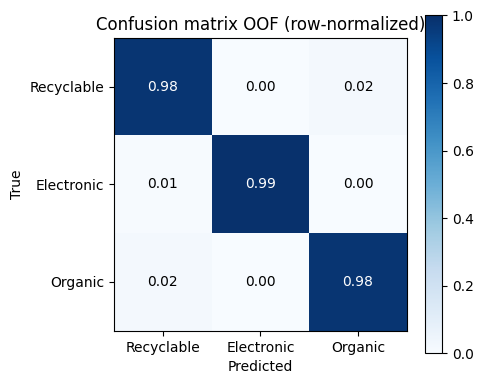

OOF disimpan: /kaggle/working/experiments/baseline_v1_convnext/oof_predictions.csv


In [23]:
oof_mask = ~np.isnan(oof_probs).any(axis=1)
print(f"OOF tersedia untuk {int(oof_mask.sum())}/{len(train_df)} baris (fold dilatih: {CFG.TRAIN_FOLDS})")
oof_pred = oof_probs[oof_mask].argmax(axis=1)
oof_true = train_df.loc[oof_mask, "label"].to_numpy()

oof_macro_f1 = f1_score(oof_true, oof_pred, average="macro")
oof_per_class = f1_score(oof_true, oof_pred, average=None, labels=list(range(CFG.NUM_CLASSES)))
per_fold = fold_summary_df["val_macro_f1"].to_numpy()
print(f"\nOOF macro F1 (pooled)      : {oof_macro_f1:.4f}")
print(f"Per-fold macro F1          : {[round(v, 4) for v in per_fold]}")
print(f"Mean±std per-fold macro F1 : {per_fold.mean():.4f} ± {per_fold.std():.4f}")
print()
print(classification_report(oof_true, oof_pred,
                            labels=list(range(CFG.NUM_CLASSES)),
                            target_names=[CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)], digits=4))

cm = confusion_matrix(oof_true, oof_pred, labels=list(range(CFG.NUM_CLASSES)), normalize="true")
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
tick_names = [CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)]
ax.set_xticks(range(CFG.NUM_CLASSES), tick_names)
ax.set_yticks(range(CFG.NUM_CLASSES), tick_names)
for i in range(CFG.NUM_CLASSES):
    for j in range(CFG.NUM_CLASSES):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix OOF (row-normalized)")
plt.colorbar(im)
plt.tight_layout()
plt.show()

oof_out = train_df.loc[oof_mask, ["relpath", "class_name", "label", "fold"]].copy()
oof_out["pred"] = oof_pred
for i in range(CFG.NUM_CLASSES):
    oof_out[f"prob_{i}"] = oof_probs[oof_mask, i]
oof_out.to_csv(CFG.EXP_DIR / "oof_predictions.csv", index=False)
print("OOF disimpan:", CFG.EXP_DIR / "oof_predictions.csv")

In [24]:
# Catat hasil ke experiments/EXPERIMENTS_LOG.md (append-only, entry lama tidak boleh ditimpa)
NOTES = ("Baseline pertama: ConvNeXtV2-Base full fine-tune, FocalLoss alpha 1/sqrt(count) + WeightedRandomSampler, "
         "augmentasi online brightness/contrast agresif (hue jitter dan blur dinonaktifkan demi throughput CPU Kaggle), "
         "dedup exact sha256.")  # sesuaikan bila perlu

entry = f"""
## {CFG.RUN_NAME} - {date.today().isoformat()}

- Backbone            : {CFG.MODEL_ID} (timm), full fine-tune, img {CFG.IMG_SIZE}
- Data                : {len(train_df)} gambar train setelah cleaning | fold dilatih: {CFG.TRAIN_FOLDS}
- Macro F1 per fold   : {", ".join(f"fold{r.fold}={r.val_macro_f1:.4f}" for r in fold_summary_df.itertuples())}
- TTA ablation (val)  : {", ".join(f"fold{r.fold}: tanpa-TTA={r.val_macro_f1_no_tta:.4f} / TTA={r.val_macro_f1_tta:.4f}" for r in fold_summary_df.itertuples())}
- Mean±std per fold   : {per_fold.mean():.4f} ± {per_fold.std():.4f}
- OOF macro F1 pooled : {oof_macro_f1:.4f}
- Per-class F1 (OOF)  : {", ".join(f"{CFG.LABEL_NAMES[i]}={oof_per_class[i]:.4f}" for i in range(CFG.NUM_CLASSES))}
- Catatan             : {NOTES}
"""
print(entry)
if CFG.SMOKE_TEST:
    print(">> SMOKE_TEST aktif: entry TIDAK ditulis ke log (bukan hasil eksperimen valid).")
else:
    CFG.LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
    with open(CFG.LOG_PATH, "a", encoding="utf-8") as f:
        f.write(entry)
    print(">> Entry ditambahkan (append) ke", CFG.LOG_PATH)
    if CFG.ON_KAGGLE:
        print(">> Di Kaggle log ini ada di /kaggle/working, unduh lalu merge ke experiments/EXPERIMENTS_LOG.md di repo lokal.")


## baseline_v1_convnext - 2026-07-05

- Backbone            : convnextv2_base.fcmae_ft_in22k_in1k (timm), full fine-tune, img 224
- Data                : 26464 gambar train setelah cleaning | fold dilatih: [0, 1, 2, 3, 4]
- Macro F1 per fold   : fold0=0.9815, fold1=0.9853, fold2=0.9807, fold3=0.9824, fold4=0.9794
- TTA ablation (val)  : fold0: tanpa-TTA=0.9810 / TTA=0.9815, fold1: tanpa-TTA=0.9844 / TTA=0.9853, fold2: tanpa-TTA=0.9809 / TTA=0.9807, fold3: tanpa-TTA=0.9819 / TTA=0.9824, fold4: tanpa-TTA=0.9784 / TTA=0.9794
- Mean±std per fold   : 0.9818 ± 0.0020
- OOF macro F1 pooled : 0.9818
- Per-class F1 (OOF)  : Recyclable=0.9751, Electronic=0.9891, Organic=0.9813
- Catatan             : Baseline pertama: ConvNeXtV2-Base full fine-tune, FocalLoss alpha 1/sqrt(count) + WeightedRandomSampler, augmentasi online brightness/contrast agresif (hue jitter dan blur dinonaktifkan demi throughput CPU Kaggle), dedup exact sha256.

>> Entry ditambahkan (append) ke /kaggle/working/experiments/EX

## 8. Generate Submission

Aturan (juknis §4-§5): data test **hanya** untuk prediksi akhir; nama file `submission_NamaTim.csv`; kolom `id,predicted`; kode 0/1/2; **urutan id persis seperti template**.

**Exact match test->train**: scan menemukan sejumlah file test yang identik byte-for-byte (sha256 sama) dengan file train. Untuk baris itu label train dipakai langsung dan prediksi model di-skip. Ini legal: tidak ada data atau label eksternal yang dipakai, hanya kesamaan internal antar file di dataset resmi kompetisi; training, validasi, dan model selection sama sekali tidak menyentuh data test. Grup train yang mixed-label tidak ikut dipetakan (ambigu, menunggu review manual). Prediksi = rata-rata probabilitas softmax seluruh fold model + TTA horizontal flip (keputusan tetap, bukan hasil tuning di test). File final ditulis ke `outputs/submission_<TEAM_NAME>.csv`; salinan arsip ikut disimpan di `experiments/baseline_v1_convnext/`. Maksimal 3 submission, pastikan OOF meyakinkan sebelum upload.

In [25]:
ckpt_prefix = "smoke_" if CFG.SMOKE_TEST else ""
ckpt_paths = sorted(CFG.EXP_DIR.glob(f"{ckpt_prefix}fold*_best.pt"))
if not CFG.SMOKE_TEST:
    ckpt_paths = [p for p in ckpt_paths if not p.name.startswith("smoke_")]
assert ckpt_paths, "Tidak ada checkpoint fold, jalankan training dulu"
print("Checkpoint dipakai:", [p.name for p in ckpt_paths])
if len(ckpt_paths) < CFG.N_FOLDS:
    print(f"PERINGATAN: baru {len(ckpt_paths)}/{CFG.N_FOLDS} fold, submission final sebaiknya memakai semua fold.")

# Susun dataframe test PERSIS mengikuti urutan id template
test_infer_df = pd.DataFrame({"id": TEMPLATE_ID_ORDER})
test_infer_df["path"] = test_infer_df["id"].map(lambda i: str(test_id_to_path[i]))
assert test_infer_df["path"].notna().all()
if CFG.SMOKE_TEST:
    test_infer_df = test_infer_df.head(CFG.SMOKE_TEST_IMAGES)
    print(f"SMOKE_TEST: inference hanya {len(test_infer_df)} gambar test pertama (cek pipeline).")

# Exact match test->train via sha256 dari tahap scan: baris test yang identik byte-for-byte dengan
# gambar train memakai label train langsung, model di-skip untuk baris itu. Legal: hanya memanfaatkan
# kesamaan di dalam dataset kompetisi itu sendiri, bukan data/label eksternal (juknis §5).
# train_df sudah bersih: unik per sha256, grup mixed-label sudah dikeluarkan, jadi mapping tidak ambigu.
hash_to_label = train_df.set_index("sha256")["label"].to_dict()
relpath_to_hash = test_scan.set_index("relpath")["sha256"].to_dict()
test_infer_df["sha256"] = [relpath_to_hash.get(str(Path(p).relative_to(CFG.DATA_ROOT))) for p in test_infer_df["path"]]
test_infer_df["match_label"] = test_infer_df["sha256"].map(hash_to_label)
matched_mask = test_infer_df["match_label"].notna().to_numpy()
print(f"Exact match test->train: {int(matched_mask.sum())}/{len(test_infer_df)} baris memakai label train langsung")

preds = np.full(len(test_infer_df), -1, dtype=int)
preds[matched_mask] = test_infer_df.loc[matched_mask, "match_label"].astype(int).to_numpy()

unmatched_df = test_infer_df[~matched_mask].reset_index(drop=True)
if len(unmatched_df):
    test_loader = DataLoader(WasteDataset(unmatched_df, eval_transform, with_target=False, safe_mode=True,
                                          img_size=CFG.IMG_SIZE, max_decode_side=CFG.MAX_DECODE_SIDE),
                             batch_size=CFG.BATCH_SIZE * 2, shuffle=False, num_workers=CFG.NUM_WORKERS,
                             pin_memory=False,  # dimatikan: cache pinned-memory suspek leak; H2D pageable hanya ~3ms lebih lambat/batch
                             prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,  # 4->2: margin RAM pasca-OOM
                             worker_init_fn=worker_init_fn if CFG.NUM_WORKERS > 0 else None)
    mean_probs = np.zeros((len(unmatched_df), CFG.NUM_CLASSES))
    for ckpt_path in ckpt_paths:
        ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        assert ckpt["model_id"] == CFG.MODEL_ID and ckpt["img_size"] == CFG.IMG_SIZE, "Checkpoint tidak cocok dengan CFG"
        assert CFG.SMOKE_TEST or not ckpt.get("smoke"), f"{ckpt_path.name} berasal dari smoke run, latih ulang full dulu"
        model = timm.create_model(CFG.MODEL_ID, pretrained=False, num_classes=CFG.NUM_CLASSES)
        model.load_state_dict(ckpt["state_dict"])
        model = maybe_data_parallel(model.to(DEVICE))
        out = run_epoch(model, test_loader, use_tta=CFG.USE_VAL_TTA, desc=f"infer {ckpt_path.stem}")
        mean_probs += out["probs"] / len(ckpt_paths)
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    preds[~matched_mask] = mean_probs.argmax(axis=1).astype(int)

assert (preds >= 0).all()
test_infer_df["predicted"] = preds
print("\nDistribusi prediksi:")
print(test_infer_df["predicted"].value_counts().rename(index=CFG.LABEL_NAMES).to_string())

Checkpoint dipakai: ['fold0_best.pt', 'fold1_best.pt', 'fold2_best.pt', 'fold3_best.pt', 'fold4_best.pt']
Exact match test->train: 97/1458 baris memakai label train langsung


infer fold0_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold0_best: batch 22/22 (100%) | 1.12s/iter | RSS 3.6GB (delta +0.0GB)


infer fold1_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold1_best: batch 22/22 (100%) | 0.83s/iter | RSS 3.6GB (delta +0.0GB)


...

[hb] infer fold2_best: batch 22/22 (100%) | 0.82s/iter | RSS 3.6GB (delta +0.0GB)


infer fold3_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold3_best: batch 22/22 (100%) | 0.84s/iter | RSS 3.6GB (delta +0.0GB)


infer fold4_best:   0%|          | 0/22 [00:00<?, ?it/s]

[hb] infer fold4_best: batch 22/22 (100%) | 0.83s/iter | RSS 3.6GB (delta +0.0GB)

Distribusi prediksi:
predicted
Organic       737
Recyclable    521
Electronic    200


In [26]:
submission_df = test_infer_df[["id", "predicted"]].copy()

# Verifikasi keras terhadap template SEBELUM menyimpan (juknis §4: format & urutan wajib persis)
ref = template_df.head(len(submission_df)) if CFG.SMOKE_TEST else template_df
assert list(submission_df.columns) == ["id", "predicted"], "Nama/urutan kolom tidak sesuai template"
assert len(submission_df) == len(ref), f"Jumlah baris {len(submission_df)} != template {len(ref)}"
assert (submission_df["id"].to_numpy() == ref["id"].to_numpy()).all(), "Urutan id TIDAK sama dengan template!"
assert submission_df["predicted"].isin([0, 1, 2]).all(), "predicted harus kode numerik 0/1/2"
assert submission_df["predicted"].notna().all()
print("Semua verifikasi format & urutan id LULUS.")

if CFG.SMOKE_TEST:
    print(">> SMOKE_TEST aktif: file submission TIDAK disimpan. Jalankan full run untuk membuat submission.")
else:
    assert CFG.TEAM_NAME != "NamaTim", "GANTI CFG.TEAM_NAME dengan nama tim sebenarnya dulu!"
    sub_path = CFG.SUBMISSION_DIR / f"submission_{CFG.TEAM_NAME}.csv"
    submission_df.to_csv(sub_path, index=False)
    submission_df.to_csv(CFG.EXP_DIR / sub_path.name, index=False)  # arsip per eksperimen
    print("Submission disimpan:", sub_path)
    comp = pd.DataFrame({
        "pred_test_%": (100 * submission_df["predicted"].value_counts(normalize=True)).round(2),
        "train_%": (100 * train_df["label"].value_counts(normalize=True)).round(2),
    }).rename(index=CFG.LABEL_NAMES)
    print("\nDistribusi prediksi test vs distribusi train (sanity check):")
    display(comp)
    print("INGAT: maksimal 3 submission, cek ulang OOF macro F1 sebelum upload.")

Semua verifikasi format & urutan id LULUS.
Submission disimpan: /kaggle/working/outputs/submission_IndomaretLabtekV.csv

Distribusi prediksi test vs distribusi train (sanity check):


,pred_test_%,train_%
Organic,50.55,47.40
Recyclable,35.73,37.75
Electronic,13.72,14.85


INGAT: maksimal 3 submission, cek ulang OOF macro F1 sebelum upload.


## Catatan Operasional

**Rerun setelah manual relabeling**: label dibaca ulang dari struktur folder setiap run, jadi:
1. Pindahkan file antar subfolder `train/<kode>_<Kelas>/` sesuai hasil review (mulai dari `experiments/baseline_v1_convnext/duplicates_mixed_label_review.csv`).
2. *Restart & Run All* dengan `SMOKE_TEST=False`. Fold di-assign ulang dengan seed sama (komposisi bisa bergeser jika daftar file berubah, bandingkan `folds.csv` antar eksperimen bila perlu).
3. Entry hasil baru otomatis ter-append ke `experiments/EXPERIMENTS_LOG.md`; entry lama jangan dihapus, itu jejak perbandingan antar eksperimen.

**Menjalankan di Kaggle**: attach dataset `riantamaputra/bdc-2026-waste-classification-dataset` (Add Input), aktifkan Internet + GPU T4 ×2 di Session options, set `SMOKE_TEST=False` dan `TEAM_NAME`, lalu jalankan headless via *Save Version -> Save & Run All (Commit)* supaya run lanjut sendiri tanpa sesi interaktif. Semua output ada di `/kaggle/working`, unduh setelah selesai (checkpoint per fold, `folds.csv`, `oof_predictions.csv`, `EXPERIMENTS_LOG.md`, `submission_<TEAM>.csv`), lalu merge log ke repo lokal.

**Kandidat eksperimen berikutnya**: image size 384, pembanding backbone (EfficientNetV2-S / DINOv3), near-duplicate check (perceptual hash) untuk memperluas antrean relabeling, ensembling antar arsitektur.